In [1]:
#session et chargement des données
import os, re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyspark.sql import SparkSession, functions as F

BASE = os.path.expanduser("~/bosch-bigdata")
os.makedirs(f"{BASE}/figures", exist_ok=True)
os.makedirs(f"{BASE}/export", exist_ok=True)

spark = (SparkSession.builder
         .appName("BoschExploration")
         .master("local[*]")
         .config("spark.driver.memory", "5g")
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

num = spark.read.parquet(f"{BASE}/data/parquet/train_numeric")
cat = spark.read.parquet(f"{BASE}/data/parquet/train_categorical")
dat = spark.read.parquet(f"{BASE}/data/parquet/train_date")
print(spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/14 12:53:02 WARN Utils: Your hostname, Vamoussa, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/14 12:53:02 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/14 12:53:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


4.2.0


In [2]:
#section 2.1, cohérence des fichiers

for nom, df in [("numeric", num), ("categorical", cat), ("date", dat)]:
    print(f"{nom:12s} : {df.count():,} lignes | {len(df.columns):,} colonnes | "
          f"{df.select('Id').distinct().count():,} Id distincts")

print("Id absents du fichier de dates     :", num.select("Id").subtract(dat.select("Id")).count())
print("Id absents du fichier catégoriel   :", num.select("Id").subtract(cat.select("Id")).count())

numeric      : 1,183,747 lignes | 970 colonnes | 1,183,747 Id distincts
categorical  : 1,183,747 lignes | 2,141 colonnes | 1,183,747 Id distincts
date         : 1,183,747 lignes | 1,157 colonnes | 1,183,747 Id distincts
Id absents du fichier de dates     : 0
Id absents du fichier catégoriel   : 0


/home/diaba/bosch-env/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

Taux moyen de valeurs manquantes : 81.1%
Colonnes manquantes à plus de 90 % : 634 sur 968
Colonnes manquantes à plus de 99 % : 227
Colonnes entièrement vides : 0


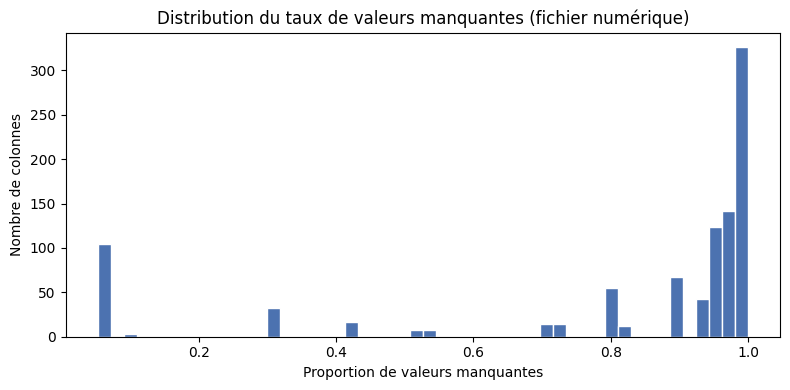

In [3]:
#section 2.2, valeurs manquantes
total = num.count()
cols = [c for c in num.columns if c not in ("Id", "Response")]
manquants = num.select([
    (F.count(F.when(F.col(c).isNull(), 1)) / total).alias(c) for c in cols
]).toPandas().T[0]
manquants.to_csv(f"{BASE}/export/manquants_numeric.csv")

print(f"Taux moyen de valeurs manquantes : {manquants.mean():.1%}")
print(f"Colonnes manquantes à plus de 90 % : {(manquants > 0.90).sum()} sur {len(manquants)}")
print(f"Colonnes manquantes à plus de 99 % : {(manquants > 0.99).sum()}")
print(f"Colonnes entièrement vides : {(manquants == 1).sum()}")

plt.figure(figsize=(8, 4))
plt.hist(manquants, bins=50, color="#4C72B0", edgecolor="white")
plt.xlabel("Proportion de valeurs manquantes")
plt.ylabel("Nombre de colonnes")
plt.title("Distribution du taux de valeurs manquantes (fichier numérique)")
plt.tight_layout()
plt.savefig(f"{BASE}/figures/fig2_2_valeurs_manquantes.png", dpi=150)
plt.show()

In [4]:
#section 2.3, construction des parcours
stations, ligne_de = {}, {}
for c in dat.columns:
    m = re.match(r"L(\d)_S(\d+)_D\d+", c)
    if m:
        s = int(m.group(2))
        stations.setdefault(s, []).append(c)
        ligne_de[s] = int(m.group(1))
stations = dict(sorted(stations.items()))
print(f"{len(stations)} stations détectées")

visites = [
    F.when(F.coalesce(*[F.col(c) for c in cols_s]).isNotNull(), 1)
     .otherwise(0).alias(f"visite_S{s}")
    for s, cols_s in stations.items()
]
parcours = dat.select("Id", *visites).join(num.select("Id", "Response"), "Id")
parcours.write.mode("overwrite").parquet(f"{BASE}/data/parquet/parcours")
print("Table des parcours enregistrée")

52 stations détectées


[Stage 45:=====================================================>  (20 + 1) / 21]

Table des parcours enregistrée


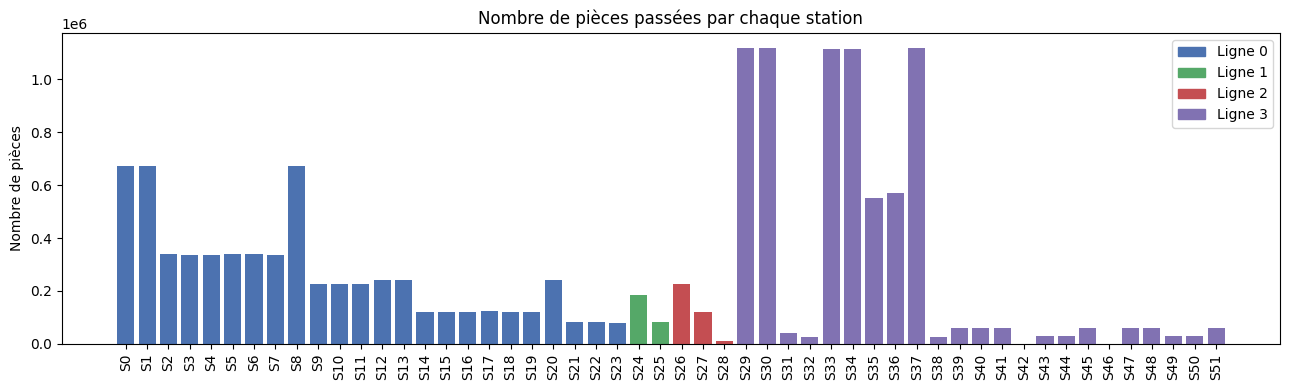

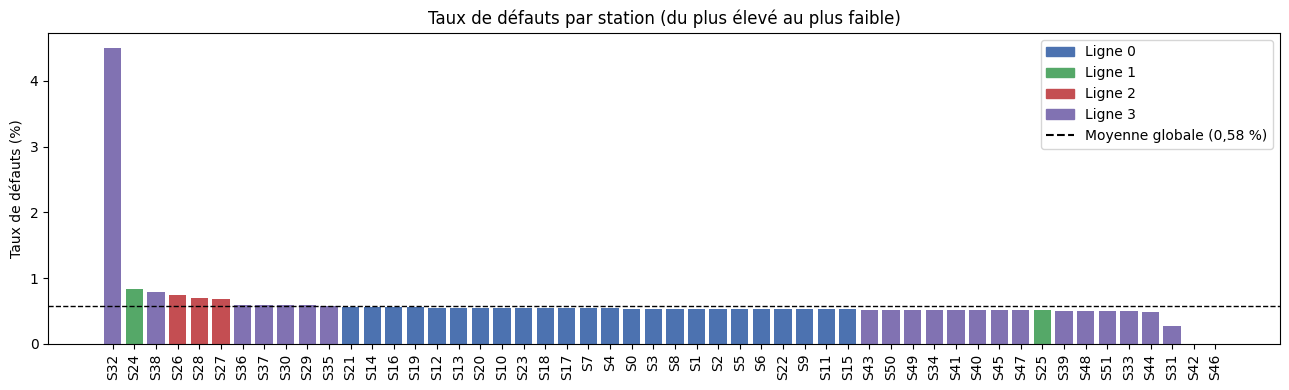

,station,ligne,pieces,defauts,taux_%
32,S32,L3,24543,1106,4.506377
24,S24,L1,183727,1521,0.827859
38,S38,L3,27142,212,0.781077
26,S26,L2,227011,1695,0.746660
28,S28,L2,9583,67,0.699155
27,S27,L2,120729,822,0.680864
36,S36,L3,569032,3391,0.595924
37,S37,L3,1120394,6556,0.585151
30,S30,L3,1119811,6551,0.585009
29,S29,L3,1119629,6546,0.584658


In [5]:
#section 2.3, défauts par station
parcours = spark.read.parquet(f"{BASE}/data/parquet/parcours")
exprs = []
for s in stations:
    exprs.append(F.sum(f"visite_S{s}").alias(f"n_{s}"))
    exprs.append(F.sum(F.col(f"visite_S{s}") * F.col("Response")).alias(f"d_{s}"))
r = parcours.agg(*exprs).collect()[0]

par_station = pd.DataFrame([
    {"station": f"S{s}", "ligne": f"L{ligne_de[s]}",
     "pieces": r[f"n_{s}"], "defauts": r[f"d_{s}"]}
    for s in stations
])
par_station["taux_%"] = 100 * par_station["defauts"] / par_station["pieces"]
par_station.to_csv(f"{BASE}/export/agregat_stations.csv", index=False)

couleurs = {"L0": "#4C72B0", "L1": "#55A868", "L2": "#C44E52", "L3": "#8172B2"}
legende = [Patch(color=c, label=f"Ligne {l[1]}") for l, c in couleurs.items()]

# Figure 2.3 : nombre de pièces par station
plt.figure(figsize=(13, 4))
plt.bar(par_station["station"], par_station["pieces"], color=par_station["ligne"].map(couleurs))
plt.xticks(rotation=90)
plt.ylabel("Nombre de pièces")
plt.title("Nombre de pièces passées par chaque station")
plt.legend(handles=legende)
plt.tight_layout()
plt.savefig(f"{BASE}/figures/fig2_3_pieces_par_station.png", dpi=150)
plt.show()

# Figure 2.4 : taux de défauts par station
tri = par_station.sort_values("taux_%", ascending=False)
plt.figure(figsize=(13, 4))
plt.bar(tri["station"], tri["taux_%"], color=tri["ligne"].map(couleurs))
plt.axhline(0.58, color="black", linestyle="--", linewidth=1, label="Moyenne globale (0,58 %)")
plt.xticks(rotation=90)
plt.ylabel("Taux de défauts (%)")
plt.title("Taux de défauts par station (du plus élevé au plus faible)")
plt.legend(handles=legende + [plt.Line2D([], [], color="black", linestyle="--", label="Moyenne globale (0,58 %)")])
plt.tight_layout()
plt.savefig(f"{BASE}/figures/fig2_4_taux_defauts_par_station.png", dpi=150)
plt.show()

tri.head(10)

In [6]:
#les parcours les plus fréquents
cols_visite = [f"visite_S{s}" for s in stations]

chemins = (parcours
    .withColumn("chemin", F.concat_ws("-", *[F.when(F.col(f"visite_S{s}") == 1, F.lit(f"S{s}")) for s in stations]))
    .withColumn("nb_stations", sum(F.col(c) for c in cols_visite)))
chemins.cache()

print("Nombre de parcours distincts :", chemins.select("chemin").distinct().count())
print("Nombre moyen de stations par pièce :", round(chemins.agg(F.avg("nb_stations")).first()[0], 1))

top = (chemins.groupBy("chemin")
       .agg(F.count("*").alias("pieces"), F.sum("Response").alias("defauts"))
       .withColumn("taux_%", F.round(100 * F.col("defauts") / F.col("pieces"), 2))
       .orderBy(F.desc("pieces")))
pd.set_option("display.max_colwidth", 120)
top.limit(10).toPandas()

Nombre de parcours distincts : 7927
Nombre moyen de stations par pièce : 12.1


/home/diaba/bosch-env/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,chemin,pieces,defauts,taux_%
0,S24-S26-S29-S30-S33-S34-S36-S37,58379,394,0.67
1,S24-S26-S29-S30-S33-S34-S35-S37,56718,383,0.68
2,S25-S26-S29-S30-S33-S34-S36-S37,23438,89,0.38
3,S25-S26-S29-S30-S33-S34-S35-S37,22561,76,0.34
4,S24-S27-S29-S30-S33-S34-S36-S37,21188,111,0.52
5,S24-S27-S29-S30-S33-S34-S35-S37,20316,127,0.63
6,S25-S27-S29-S30-S33-S34-S36-S37,10916,35,0.32
7,S0-S1-S2-S5-S6-S8-S11-S29-S30-S33-S34-S36-S37,10613,37,0.35
8,S25-S27-S29-S30-S33-S34-S35-S37,10609,34,0.32
9,S0-S1-S2-S5-S6-S8-S9-S29-S30-S33-S34-S36-S37,10536,48,0.46


/home/diaba/bosch-env/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


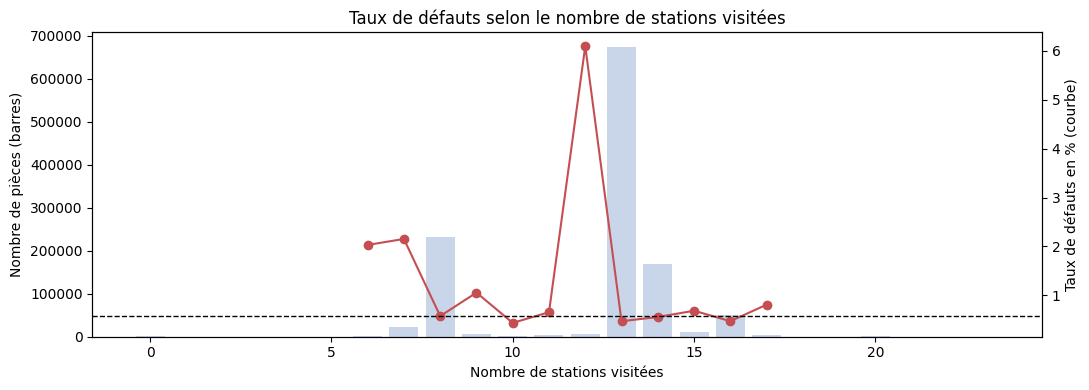

In [7]:
#taux de défauts selon le nombre de stations visitées
par_nb = (chemins.groupBy("nb_stations")
          .agg(F.count("*").alias("pieces"), F.sum("Response").alias("defauts"))
          .orderBy("nb_stations").toPandas())
par_nb["taux_%"] = 100 * par_nb["defauts"] / par_nb["pieces"]
fiable = par_nb[par_nb["pieces"] >= 1000]

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(par_nb["nb_stations"], par_nb["pieces"], color="#C9D6EA")
ax1.set_xlabel("Nombre de stations visitées")
ax1.set_ylabel("Nombre de pièces (barres)")
ax2 = ax1.twinx()
ax2.plot(fiable["nb_stations"], fiable["taux_%"], color="#C44E52", marker="o")
ax2.axhline(0.58, color="black", linestyle="--", linewidth=1)
ax2.set_ylabel("Taux de défauts en % (courbe)")
plt.title("Taux de défauts selon le nombre de stations visitées")
plt.tight_layout()
plt.savefig(f"{BASE}/figures/fig2_6_defauts_nb_stations.png", dpi=150)
plt.show()

In [11]:
chemins.filter("nb_stations = 12").agg(
    F.count("*").alias("pieces"),
    F.sum("Response").alias("defauts"),
    F.round(100 * F.avg("visite_S32"), 1).alias("%_passant_par_S32")
).show()

+------+-------+-----------------+
|pieces|defauts|%_passant_par_S32|
+------+-------+-----------------+
|  7221|    440|             34.5|
+------+-------+-----------------+



In [12]:
chemins.filter("nb_stations = 12").groupBy("visite_S32").agg(
    F.count("*").alias("pieces"), F.sum("Response").alias("defauts")
).withColumn("taux_%", F.round(100 * F.col("defauts") / F.col("pieces"), 2)).show()

+----------+------+-------+------+
|visite_S32|pieces|defauts|taux_%|
+----------+------+-------+------+
|         0|  4730|     19|   0.4|
|         1|  2491|    421|  16.9|
+----------+------+-------+------+



In [8]:
#calcul des temps de passage
cols_date = [c for c in dat.columns if c != "Id"]
temps = (dat.select("Id",
                    F.least(*cols_date).alias("t_debut"),
                    F.greatest(*cols_date).alias("t_fin"))
         .join(num.select("Id", "Response"), "Id")
         .withColumn("duree", F.col("t_fin") - F.col("t_debut"))
         .withColumn("periode", F.floor(F.col("t_debut") / 10)))
temps.write.mode("overwrite").parquet(f"{BASE}/data/parquet/temps")
temps = spark.read.parquet(f"{BASE}/data/parquet/temps")

bornes = temps.select(F.min("t_debut"), F.max("t_fin")).first()
print(f"Période couverte : de {bornes[0]} à {bornes[1]} unités de temps")
print("Pièces sans aucun horodatage :", temps.filter(F.col("t_debut").isNull()).count())

Période couverte : de 0.0 à 1718.48 unités de temps
Pièces sans aucun horodatage : 582


/home/diaba/bosch-env/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


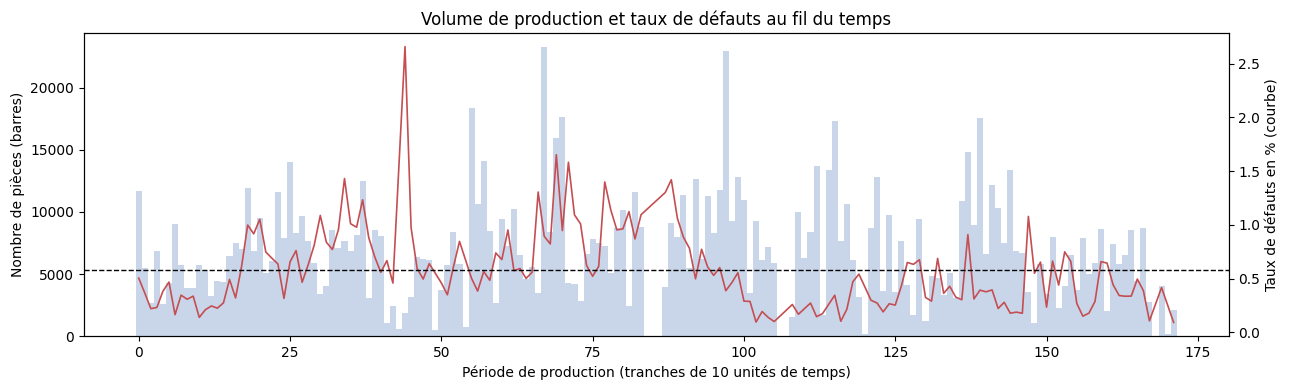

In [9]:
#évolution du taux de défauts dans le temps
par_periode = (temps.filter(F.col("periode").isNotNull())
               .groupBy("periode")
               .agg(F.count("*").alias("pieces"), F.sum("Response").alias("defauts"))
               .orderBy("periode").toPandas())
par_periode["taux_%"] = 100 * par_periode["defauts"] / par_periode["pieces"]
par_periode.to_csv(f"{BASE}/export/agregat_periodes.csv", index=False)
fiable = par_periode[par_periode["pieces"] >= 1000]

fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.bar(par_periode["periode"], par_periode["pieces"], color="#C9D6EA", width=1)
ax1.set_xlabel("Période de production (tranches de 10 unités de temps)")
ax1.set_ylabel("Nombre de pièces (barres)")
ax2 = ax1.twinx()
ax2.plot(fiable["periode"], fiable["taux_%"], color="#C44E52", linewidth=1.2)
ax2.axhline(0.58, color="black", linestyle="--", linewidth=1)
ax2.set_ylabel("Taux de défauts en % (courbe)")
plt.title("Volume de production et taux de défauts au fil du temps")
plt.tight_layout()
plt.savefig(f"{BASE}/figures/fig2_7_defauts_dans_le_temps.png", dpi=150)
plt.show()

/home/diaba/bosch-env/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


+--------+-------------+-------------+
|Response|duree_mediane|duree_moyenne|
+--------+-------------+-------------+
|       0|         3.69|         10.7|
|       1|         4.93|        13.91|
+--------+-------------+-------------+



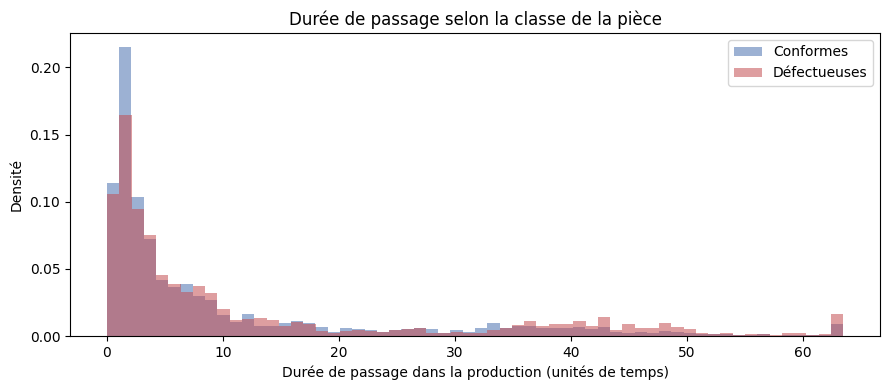

In [10]:
#durée de passage, pièces conformes et défectueuses
temps.groupBy("Response").agg(
    F.round(F.percentile_approx("duree", 0.5), 2).alias("duree_mediane"),
    F.round(F.avg("duree"), 2).alias("duree_moyenne")
).orderBy("Response").show()

ech = (temps.filter(F.col("duree").isNotNull())
       .sampleBy("Response", {0: 0.05, 1: 1.0}, seed=42)
       .select("duree", "Response").toPandas())
limite = ech["duree"].quantile(0.99)

plt.figure(figsize=(9, 4))
for r, couleur, nom in [(0, "#4C72B0", "Conformes"), (1, "#C44E52", "Défectueuses")]:
    plt.hist(ech.loc[ech["Response"] == r, "duree"].clip(upper=limite),
             bins=60, density=True, alpha=0.55, color=couleur, label=nom)
plt.xlabel("Durée de passage dans la production (unités de temps)")
plt.ylabel("Densité")
plt.title("Durée de passage selon la classe de la pièce")
plt.legend()
plt.tight_layout()
plt.savefig(f"{BASE}/figures/fig2_8_duree_passage.png", dpi=150)
plt.show()

In [1]:
   !cp -r ~/bosch-bigdata/notebooks /mnt/c/Users/diaba/Desktop/bosch_notebooks